In [14]:
import warnings

# Ignore all warnings
warnings.filterwarnings("ignore")

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [15]:
df = pd.read_csv(r'C:\Users\ss\OneDrive\Desktop\CUSTOMER PREDICTION\Data\cleaned_data.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,0,0,0,0,0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2216 entries, 0 to 2215
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2216 non-null   int64  
 1   Year_Birth           2216 non-null   int64  
 2   Education            2216 non-null   object 
 3   Marital_Status       2216 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2216 non-null   int64  
 6   Teenhome             2216 non-null   int64  
 7   Dt_Customer          2216 non-null   object 
 8   Recency              2216 non-null   int64  
 9   MntWines             2216 non-null   int64  
 10  MntFruits            2216 non-null   int64  
 11  MntMeatProducts      2216 non-null   int64  
 12  MntFishProducts      2216 non-null   int64  
 13  MntSweetProducts     2216 non-null   int64  
 14  MntGoldProds         2216 non-null   int64  
 15  NumDealsPurchases    2216 non-null   i

**Distribution of Numerical Columns**


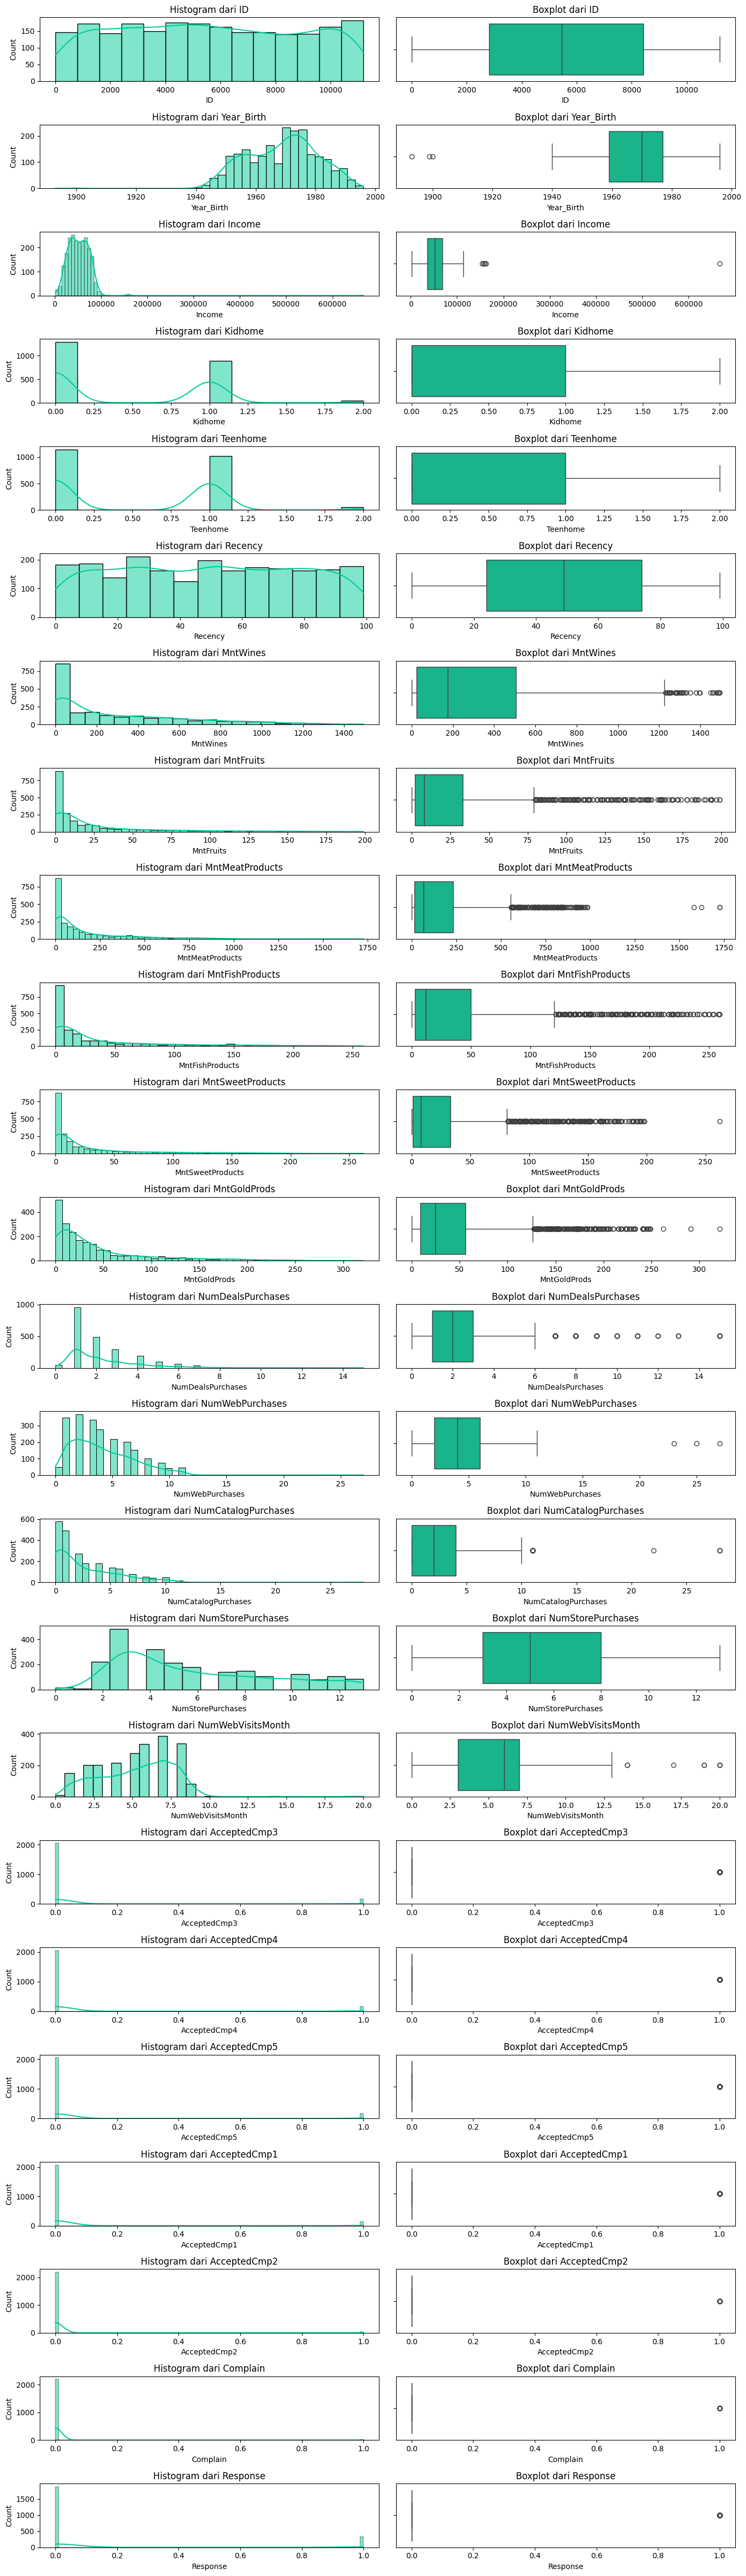

In [18]:
num = [column for column in df.columns if df[column].dtypes != 'object']

# histogram and boxplot
fig, axes = plt.subplots(nrows=len(num), ncols=2, figsize=(14, 2*len(num)))

for i, column in enumerate(num):
    # Histogram
    sns.histplot(df[column], ax=axes[i, 0], kde=True,color='#00cc99')
    axes[i, 0].set_title(f'Histogram dari {column}')

    # Boxplot
    sns.boxplot(data=df, x=column, ax=axes[i, 1], orient='h',color='#00cc99')
    axes[i, 1].set_title(f'Boxplot dari {column}')

plt.tight_layout()
plt.show()

To gain a deeper understanding, let’s identify the outliers in the numerical data.

Since some features exhibit extreme outliers, the subsequent analysis will use the **median** instead of the **mean**, as the mean can be skewed by those extreme values.

**Distribution of Categorical Columns**

In [19]:
def annotate_bar_plot(ax):
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.0f}',  
                    (bar.get_x() + bar.get_width() / 2., bar.get_height()),  
                    ha='center', va='center',  
                    xytext=(0, -7),  
                    textcoords='offset points',  
                    fontsize=9, color='white', fontweight='semibold')


def annotate_bar_plot_percent(ax, total):
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(f'{height/total:.2%}',  
                    (bar.get_x() + bar.get_width() / 2., height),  
                    ha='center', va='center',  
                    xytext=(0, 12),  
                    textcoords='offset points',  
                    fontsize=9, color='black', fontweight='semibold')


def plot_categorical_distribution(categorical, ncols=2, palette="viridis"):
    obj_cols = categorical.select_dtypes(include="object").columns.tolist()
    total = len(categorical)
    
    nrows = (len(obj_cols) + ncols - 1) // ncols  # hitung jumlah baris
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(8*ncols, 4*nrows))
    axes = axes.flatten()

    for i, col in enumerate(obj_cols):
        ax = axes[i]
        sns.countplot(data=categorical, x=col, ax=ax, palette=palette, order=categorical[col].value_counts().index,hue=categorical[col])
        ax.set_title(f"Distribusi {col}")
        ax.tick_params(axis="x", rotation=45)

    
        annotate_bar_plot(ax)
        annotate_bar_plot_percent(ax, total)

    
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.style.use('ggplot')
    plt.show()


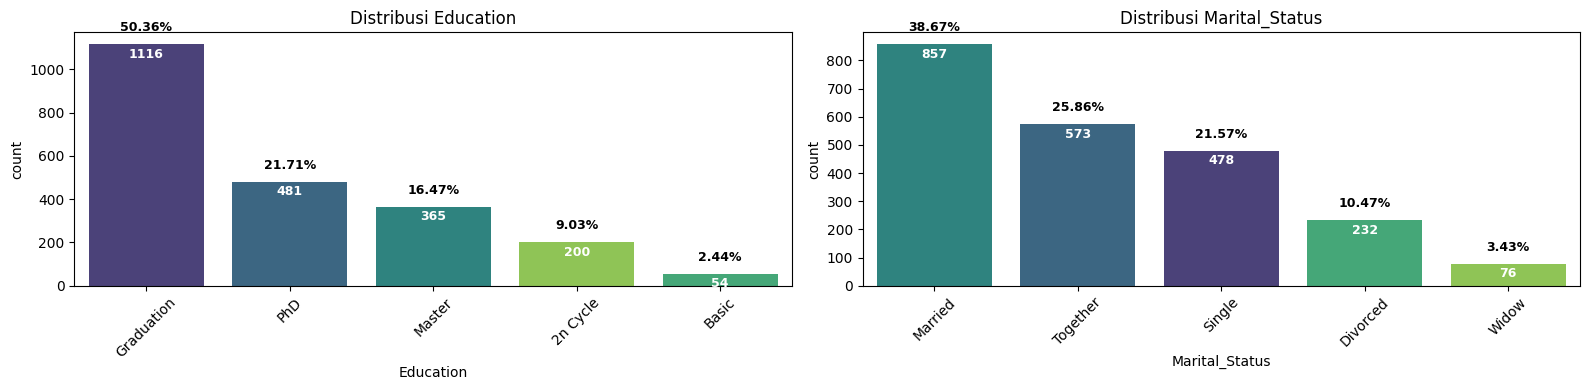

In [20]:
categorical = df[['Education', 'Marital_Status']]
plot_categorical_distribution(categorical)

**Handle Outliers**

In [21]:
def calculate_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

outlier_data = []

numerical = [var for var in df.columns if df[var].dtypes != 'object']

for column in numerical:
    outlier_result, lower_bound, upper_bound = calculate_outliers(df, column)
    total_outlier = len(outlier_result)
    outlier_percentage = round(total_outlier / len(df[column]) * 100, 2)
    outlier_data.append([column, total_outlier, outlier_percentage, lower_bound, upper_bound])

outlier_df = pd.DataFrame(outlier_data, columns=["Column", "Total Outliers", "Percentage (%)", "Lower Bound", "Upper Bound"])
outlier_df

,Column,Total Outliers,Percentage (%),Lower Bound,Upper Bound
0,ID,0,0.00,-5595.750,16832.250
1,Year_Birth,3,0.14,1932.000,2004.000
2,Income,8,0.36,-14525.500,118350.500
3,Kidhome,0,0.00,-1.500,2.500
4,Teenhome,0,0.00,-1.500,2.500
5,Recency,0,0.00,-51.000,149.000
6,MntWines,35,1.58,-697.500,1226.500
7,MntFruits,246,11.10,-44.500,79.500
8,MntMeatProducts,174,7.85,-308.375,556.625
9,MntFishProducts,222,10.02,-67.500,120.500


 I have to determine whether each outlier represents an error, a legitimate customer behavior, or a variable for which the IQR method is inappropriate, before deciding the appropriate treatment ie. Correct or impute or remove or Keep legitimate outliers 

In [22]:
df[df['Year_Birth'] < 1932]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
181,7829,1900,2n Cycle,Divorced,36640.0,1,0,2013-09-26,99,15,...,1,2,5,0,0,0,0,0,1,0
228,11004,1893,2n Cycle,Single,60182.0,0,1,2014-05-17,23,8,...,0,2,4,0,0,0,0,0,0,0
326,1150,1899,PhD,Together,83532.0,0,0,2013-09-26,36,755,...,6,4,1,0,0,1,0,0,0,0


Confirmed three outliers in birth year data, so those rows will be removed.

Outliers in Response, Complain, and AcceptedCmp1 - AcceptedCmp5 are variables for which the IQR method is inappropriate. This is because there are only two entries ie 0,1 in this columns.

I won't investigate the remaining columns since i don't need them for the training of the model.

In [23]:
#Drop outliers
df = df[df['Year_Birth'] > 1932].reset_index(drop=True)

In [24]:
#Drop columns irrelevant columns
df = df.drop(columns=['NumWebVisitsMonth','Dt_Customer','NumStorePurchases','NumCatalogPurchases','NumWebPurchases','NumDealsPurchases','MntGoldProds','MntSweetProducts','ID','Kidhome','Teenhome','MntWines','MntFruits','MntMeatProducts','MntFishProducts'])

In [25]:
#Export Data
df.to_csv(r'C:\Users\ss\OneDrive\Desktop\CUSTOMER PREDICTION\Data\preprocesed_data.csv', index=False, header=True)